# Lesion Classification: Dataset Preparation


Prepare labeled image crops for conventional machine learning and convolutional neural networks. The target labels are **PAI 3, PAI 4, and PAI 5**. These crops support *severity classification of annotated regions*, not healthy-versus-diseased diagnosis.

## Load annotations

Read the CSV generated in "02_Data_Preparation.ipynb" Run this notebook from the notebooks folder.

In [1]:
from pathlib import Path
from collections import Counter
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

#Locate the annotation table and the output folder for lesion crops
DATASET_CSV = Path("../results/dataset_annotations.csv")
CROPS_DIR = Path("../dataset/lesion_crops")

#Load one annotation per row, including its split and PAI class
df = pd.read_csv(DATASET_CSV)

#Confirm that the required columns and labels are available
required = {"image", "split", "class", "xmin", "ymin", "xmax", "ymax"}
assert required.issubset(df.columns), "Missing columns in annotation CSV"
assert set(df["class"].unique()) == {3, 4, 5}, "Unexpected PAI labels"

print("Total annotations:", len(df))
print("Classes:", sorted(df["class"].unique()))
print("Annotations by split:", df["split"].value_counts().to_dict())

Total annotations: 6631
Classes: [np.int64(3), np.int64(4), np.int64(5)]
Annotations by split: {'train': 4573, 'validation': 1058, 'test': 1000}


## Extract lesion crops

Use the original bounding boxes to crop each annotated region. The image is resized to **128 × 128 pixels** for a lightweight initial baseline. This may stretch very small regions; later experiments can compare crops with extra surrounding context.

The crop files are organized by **split and PAI class**, preserving the radiograph-level train/test separation. This step can take several minutes.

In [2]:
#Create a separate directory for each split and PAI class
for split in ["train", "validation", "test"]:
    for label in [3, 4, 5]:
        (CROPS_DIR / split / str(label)).mkdir(parents=True, exist_ok=True)

#Track how many valid lesion crops are saved
saved = Counter()

#Group rows by radiograph to avoid reopening the same large image
for image_path, group in df.groupby("image", sort=False):
    with Image.open(image_path) as source:
        image = source.convert("RGB")

    width, height = image.size

    for index, row in group.iterrows():
        #Keep bounding-box coordinates within the image boundaries
        x1 = max(0, int(row["xmin"]))
        y1 = max(0, int(row["ymin"]))
        x2 = min(width, int(row["xmax"]))
        y2 = min(height, int(row["ymax"]))

        #Skip empty or invalid bounding boxes
        if x2 <= x1 or y2 <= y1:
            continue

        #Extract the annotated lesion and resize for classification
        crop = image.crop((x1, y1, x2, y2))
        crop = crop.resize((128, 128), Image.Resampling.LANCZOS)

        #Save using the annotation index to avoid filename collisions
        split = row["split"]
        label = int(row["class"])
        output = CROPS_DIR / split / str(label) / f"lesion_{index:05d}.jpg"
        crop.save(output, quality=90)
        saved[split] += 1

#Print results after all images have been processed
print("Saved crops:", dict(saved))
print("Total saved:", sum(saved.values()))
print("Expected annotations:", len(df))

Saved crops: {'train': 4573, 'validation': 1058, 'test': 1000}
Total saved: 6631
Expected annotations: 6631


## Inspect sample crops

Display three training crops from each class. Visual inspection is important because some annotated regions are small or contain limited surrounding anatomy.

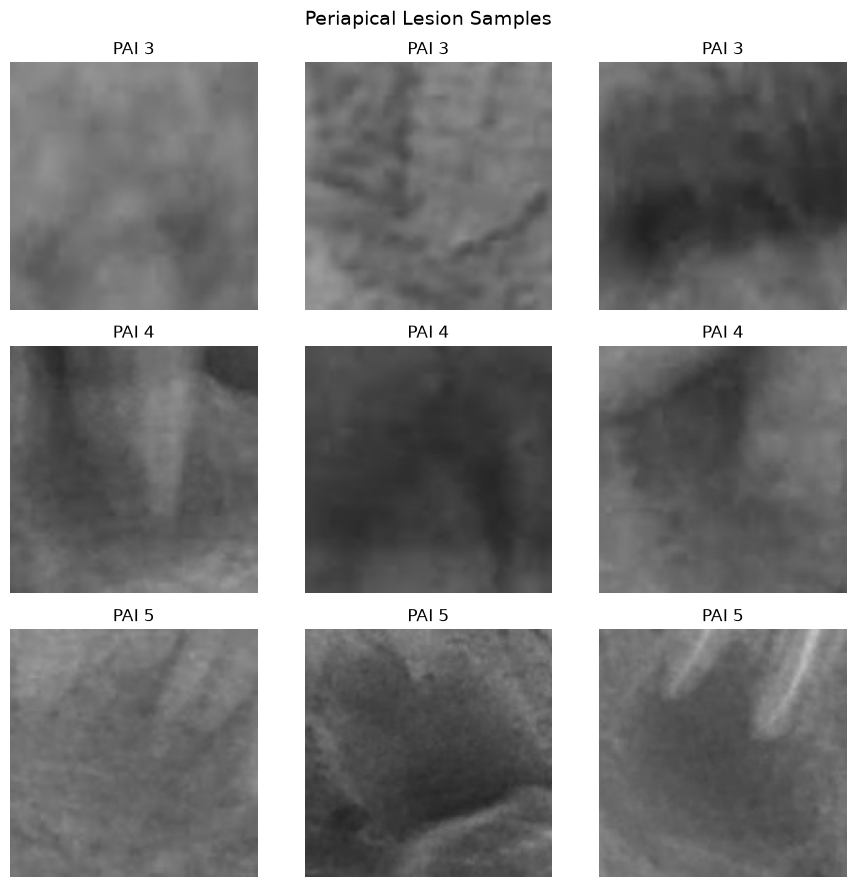

In [3]:
#Show three lesion examples from each PAI class
fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for row, label in enumerate([3, 4, 5]):
    #Use training examples only for this preview
    files = sorted((CROPS_DIR / "train" / str(label)).glob("*.jpg"))

    for col in range(3):
        ax = axes[row, col]
        if col < len(files):
            with Image.open(files[col]) as image:
                ax.imshow(image)
        ax.set_title(f"PAI {label}")
        ax.axis("off")

plt.suptitle("Periapical Lesion Samples", fontsize=14)
plt.tight_layout()
plt.show()

## Plot class distribution

Compare annotation counts by PAI class and data split. Because PAI 3 is more common than PAI 5, later model evaluation should include **macro F1-score** and **per-class recall**, not accuracy alone.

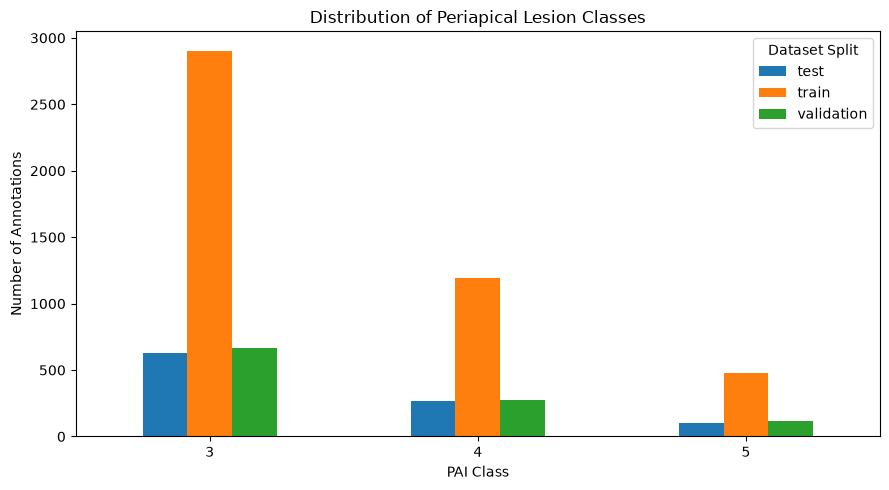

split  test  train  validation
class                         
3       628   2904         666
4       269   1193         274
5       103    476         118


In [4]:
#Count the number of annotated lesions for each split and PAI class
counts = pd.crosstab(df["class"], df["split"])

#Create a grouped bar chart for the final project report
counts.plot(kind="bar", figsize=(9, 5))
plt.title("Distribution of Periapical Lesion Classes")
plt.xlabel("PAI Class")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=0)
plt.legend(title="Dataset Split")
plt.tight_layout()
plt.show()

#Print the exact counts alongside the visualization
print(counts)